# R2a — ACCIDENT: clips con y sin incidente + línea base oficial (Qwen sin LoRA)

## Por qué necesitamos clips sin incidente

Piensa en un **detector de humo que suena siempre**: detecta el 100 % de los incendios (recall perfecto), pero nadie le hace caso porque también suena cuando no pasa nada. En R1 Qwen dijo "incidente" en **todos** los clips, y todos tenían incidente: con eso no sabemos si ve el choque o si es el detector que siempre suena.

Para medir **precisión** y **falsas alarmas** hacen falta clips donde *no* pase nada. Y para el LoRA también: si solo lo entrenamos con choques, aprende a decir "sí" siempre.

## De dónde salen los negativos

ACCIDENT (Picek et al., CVPR 2026) tiene 2,027 clips **reales de CCTV** y 2,211 sintéticos (CARLA). **Todos contienen un choque**, pero cada uno trae anotado **el segundo del choque**, la ubicación y el tipo. Entonces de cada video se cortan dos ventanas:

```
video:   |------- tráfico normal -------|··margen··|💥 choque|-----|
                 ventana NEGATIVA                ventana POSITIVA
```

Ventaja: el negativo y el positivo salen de **la misma cámara, misma luz, mismo clima**. La única diferencia es el choque, así que el modelo no puede acertar "adivinando" por el fondo.

**Tipos de choque de ACCIDENT** (5): frontal (*head-on*), por alcance (*rear-end*), en T (*t-bone*), roce lateral (*sideswipe*) y un solo vehículo (*single*). Se alinea el JSON del supervisor a esas clases.

**Ojo para R2 (el LoRA):** un paper sobre CCTV de accidentes reporta que colecciones de Kaggle traen clips casi duplicados que se cuelan entre train y test. Por eso el split será **por video/fuente**, nunca por ventana.

**Antes de empezar:** T4 GPU y el token de Kaggle en *Secretos* (🔑 en la barra izquierda) con el nombre `KAGGLE_API_TOKEN` y acceso al notebook activado.

## 0. Instalación

In [ ]:
%pip install -q "transformers>=4.51" accelerate "qwen-vl-utils[decord]" bitsandbytes huggingface_hub opencv-python-headless pandas matplotlib "kaggle>=1.7"

In [ ]:
import os, re, json, time, glob, zipfile, random, shutil, subprocess, io
import torch
import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

assert torch.cuda.is_available(), "No hay GPU: Entorno de ejecución → Cambiar tipo de entorno → T4 GPU"
p = torch.cuda.get_device_properties(0)
print(f"GPU: {p.name} · {p.total_memory/1e9:.1f} GB · compute {p.major}.{p.minor}")

DIR_DATOS = os.environ.get("ROADVISION_DATA", "/content/datos_roadvision")
DIR_ACC = os.path.join(DIR_DATOS, "accident")             # archivos de Kaggle
DIR_MUESTRAS = DIR_ACC                                     # para reutilizar funciones de R1
DIR_CLIPS = os.path.join(DIR_DATOS, "clips_accident")      # frames de cada ventana
DIR_RESULTADOS = os.path.join(DIR_DATOS, "resultados_qwen")
for d in (DIR_ACC, DIR_CLIPS, DIR_RESULTADOS):
    os.makedirs(d, exist_ok=True)
EXT_VIDEO = (".mp4", ".mov", ".avi", ".mkv", ".webm", ".m4v")
random.seed(0); np.random.seed(0)

GPU: Tesla T4 · 15.6 GB · compute 7.5


### (Opcional) Google Drive

Recomendado aquí: bajar videos de Kaggle tarda, y con Drive no los vuelves a bajar en la siguiente sesión.

In [ ]:
USAR_DRIVE = False

if USAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DIR_DATOS = "/content/drive/MyDrive/roadvision"
    DIR_ACC = DIR_MUESTRAS = os.path.join(DIR_DATOS, "accident")
    DIR_CLIPS = os.path.join(DIR_DATOS, "clips_accident")
    DIR_RESULTADOS = os.path.join(DIR_DATOS, "resultados_qwen")
    for d in (DIR_ACC, DIR_CLIPS, DIR_RESULTADOS):
        os.makedirs(d, exist_ok=True)
    print("Usando Drive:", DIR_DATOS)

## 1. Kaggle: inventario sin descargar

Primero solo se **listan** los archivos del dataset (nombre y tamaño), igual que en R0. Así sabemos cuánto pesa antes de bajar nada.

In [ ]:
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
DATASET = "picekl/accident"


def kaggle(*args, timeout=300):
    """Corre el CLI de Kaggle. Nunca se queda colgado: si tarda más de `timeout` s, avisa y truena."""
    try:
        r = subprocess.run(["kaggle", *args], capture_output=True, text=True, timeout=timeout,
                           stdin=subprocess.DEVNULL)          # si pidiera algo por teclado, falla en vez de esperar
    except subprocess.TimeoutExpired:
        raise RuntimeError(f"kaggle {' '.join(args[:3])} tardó más de {timeout} s")
    if r.returncode != 0:
        raise RuntimeError(r.stderr or r.stdout)
    return r.stdout


print("Versión del CLI:", kaggle("--version", timeout=60).strip())
print("Probando sesión de Kaggle...", end=" ", flush=True)
kaggle("datasets", "list", "-s", "accident", timeout=60)
print("OK")

# Las opciones cambian entre versiones del CLI: se revisan antes de usarlas
AYUDA_FILES = kaggle("datasets", "files", "-h", timeout=60)
PAGINAS = "--page-token" in AYUDA_FILES and "--page-size" in AYUDA_FILES
print("¿Soporta paginación en 'datasets files'?", PAGINAS)


# Lista paginada de archivos (CSV: name,size,creationDate)
filas, token, vistos = [], None, set()
t0 = time.time()
for pagina in range(1, 101):                    # tope de seguridad: 100 páginas = 20,000 archivos
    args = ["datasets", "files", DATASET, "--csv"]
    if PAGINAS:
        args += ["--page-size", "200"] + (["--page-token", token] if token else [])
    salida = kaggle(*args)
    m = re.search(r"Next Page Token = (\S+)", salida)
    texto_csv = re.sub(r"Next Page Token = \S+\s*", "", salida)          # puede venir antes o después de la tabla
    texto_csv = texto_csv[texto_csv.find("name,"):] if "name," in texto_csv else texto_csv
    filas.append(pd.read_csv(io.StringIO(texto_csv)))
    print(f"  página {pagina}: {sum(len(f) for f in filas)} archivos · {time.time()-t0:.0f} s", flush=True)
    if not PAGINAS or not m or m.group(1) in vistos:           # sin más páginas, o el CLI repite la misma
        break
    token = m.group(1); vistos.add(token)

archivos = pd.concat(filas, ignore_index=True)
archivos.columns = [c.strip().lower() for c in archivos.columns]


def a_bytes(s):
    if isinstance(s, (int, float)):
        return float(s)
    m = re.match(r"([\d.]+)\s*([KMGT]?B)", str(s).strip(), re.I)
    if not m:
        return np.nan
    return float(m.group(1)) * {"B": 1, "KB": 1e3, "MB": 1e6, "GB": 1e9, "TB": 1e12}[m.group(2).upper()]


archivos["bytes"] = archivos["size"].map(a_bytes)
archivos["ext"] = archivos["name"].str.extract(r"(\.[^./]+)$")[0].str.lower()
archivos["carpeta"] = archivos["name"].str.split("/").str[0]
print(f"{len(archivos)} archivos · {archivos['bytes'].sum()/1e9:.1f} GB en total")
display(archivos.groupby(["carpeta", "ext"]).agg(n=("name", "size"), GB=("bytes", lambda b: round(b.sum()/1e9, 2))))
display(archivos[~archivos["ext"].isin(EXT_VIDEO)].head(30))

Versión del CLI: Warning: Looks like you're using an outdated `kaggle` version (installed: 2.0.2), please consider upgrading to the latest version (2.2.5)
Kaggle CLI 2.0.2
Probando sesión de Kaggle... OK
¿Soporta paginación en 'datasets files'? True
  página 1: 200 archivos · 2 s
  página 2: 400 archivos · 3 s
  página 3: 600 archivos · 5 s
  página 4: 800 archivos · 7 s
  página 5: 1000 archivos · 8 s
  página 6: 1200 archivos · 9 s
  página 7: 1400 archivos · 10 s
  página 8: 1600 archivos · 12 s
  página 9: 1800 archivos · 13 s
  página 10: 2000 archivos · 14 s
  página 11: 2200 archivos · 15 s
  página 12: 2400 archivos · 18 s
  página 13: 2600 archivos · 21 s
  página 14: 2800 archivos · 22 s
  página 15: 3000 archivos · 23 s
  página 16: 3200 archivos · 25 s
  página 17: 3400 archivos · 26 s
  página 18: 3600 archivos · 28 s
  página 19: 3800 archivos · 30 s
  página 20: 4000 archivos · 31 s
  página 21: 4200 archivos · 33 s
  página 22: 4400 archivos · 35 s
  página 23: 4600 arc

n     GB
carpeta                 ext               
annotation_classes.yaml .yaml     1   0.00
metadata-real.csv       .csv      1   0.00
metadata-synthetic.csv  .csv      1   0.00
real_videos             .mp4   2027   4.92
synthetic_videos        .json  2211   3.51
                        .mp4   2211  11.73

,name,size,creationdate,bytes,ext,carpeta
0,annotation_classes.yaml,321,2026-04-10 21:09:34.483000,321.0,.yaml,annotation_classes.yaml
1,metadata-real.csv,486740,2026-04-10 21:09:34.674000,486740.0,.csv,metadata-real.csv
2,metadata-synthetic.csv,619584,2026-04-10 21:09:34.614000,619584.0,.csv,metadata-synthetic.csv
2030,synthetic_videos/annotations/Town03_head-on_cl...,1336055,2026-04-10 21:12:56.772000,1336055.0,.json,synthetic_videos
2031,synthetic_videos/annotations/Town03_head-on_cl...,1978656,2026-04-10 21:12:58.602000,1978656.0,.json,synthetic_videos
2032,synthetic_videos/annotations/Town03_head-on_cl...,1291676,2026-04-10 21:12:59.984000,1291676.0,.json,synthetic_videos
2033,synthetic_videos/annotations/Town03_head-on_cl...,2121999,2026-04-10 21:13:02.952000,2121999.0,.json,synthetic_videos
2034,synthetic_videos/annotations/Town03_head-on_cl...,1317001,2026-04-10 21:13:03.941000,1317001.0,.json,synthetic_videos
2035,synthetic_videos/annotations/Town03_head-on_cl...,1049173,2026-04-10 21:13:02.199000,1049173.0,.json,synthetic_videos
2036,synthetic_videos/annotations/Town03_head-on_cl...,1377181,2026-04-10 21:13:01.748000,1377181.0,.json,synthetic_videos


## 2. Bajar las anotaciones y leerlas

Se bajan **solo** las tablas generales de anotaciones. Los sintéticos traen un archivo de anotación **por video** (cajas, máscaras, trayectorias): son miles, y bajarlos uno por uno con Kaggle tarda horas. Por eso se saltan los archivos que siguen un patrón de "uno por video"; la celda dice cuántos saltó y nunca baja más de 30 sin avisar.

In [ ]:
EXT_TABLA = (".csv", ".json", ".parquet", ".txt")
MAX_REPETICIONES = 5     # un patrón de nombre que se repite más = anotación por video → se salta
MAX_TABLAS = 30          # freno de seguridad: nunca bajar más de esto sin revisarlo

texto = archivos[archivos["ext"].isin(EXT_TABLA) & (archivos["bytes"] < 200e6)].copy()
# Tres señales de "un archivo por video":
#  1) el nombre con los dígitos cambiados por # se repite (ann/000123.json, ann/000124.json, ...)
#  2) el mismo nombre de archivo aparece en muchas carpetas (000123/meta.json, 000124/meta.json, ...)
#  3) el archivo se llama igual que un video (abc.json junto a abc.mp4)
texto["patron"] = texto["name"].str.replace(r"\d+", "#", regex=True)
texto["base"] = texto["name"].map(os.path.basename)
stems_video = set(archivos[archivos["ext"].isin(EXT_VIDEO)]["name"].map(
    lambda n: os.path.splitext(os.path.basename(n))[0]))
por_video = ((texto.groupby("patron")["name"].transform("count") > MAX_REPETICIONES)
             | (texto.groupby("base")["name"].transform("count") > MAX_REPETICIONES)
             | texto["name"].map(lambda n: os.path.splitext(os.path.basename(n))[0] in stems_video))
tablas = texto[~por_video].sort_values("bytes", ascending=False)["name"].tolist()

print(f"Archivos de texto en el dataset: {len(texto)} · por video (se saltan): {int(por_video.sum())} "
      f"· tablas generales: {len(tablas)}")
print("Ejemplos saltados:", texto[por_video]["name"].head(3).tolist())
print("Se bajan:", tablas[:MAX_TABLAS])
if not tablas:
    raise RuntimeError("No se encontró ninguna tabla general. Pásale a Claude la lista de ejemplos saltados.")
if len(tablas) > MAX_TABLAS:
    raise RuntimeError(f"Hay {len(tablas)} candidatas: demasiadas. Pásale a Claude la lista impresa arriba.")

for nombre in tablas:
    print("  bajando", nombre, flush=True)
    destino = os.path.join(DIR_ACC, nombre)
    if not os.path.exists(destino):
        kaggle("datasets", "download", DATASET, "-f", nombre, "-p", os.path.dirname(destino) or DIR_ACC, "--unzip")
        # algunos archivos llegan como nombre.zip
        z = destino + ".zip"
        if os.path.exists(z):
            with zipfile.ZipFile(z) as zz:
                zz.extractall(os.path.dirname(destino))
            os.remove(z)
print("Anotaciones bajadas:", tablas)

zips_grandes = archivos[(archivos["ext"] == ".zip") & (archivos["bytes"] > 1e9)]
if len(zips_grandes):
    print("\n⚠️  Hay ZIP grandes; los videos podrían venir dentro:")
    display(zips_grandes[["name", "size"]])

TABLAS = {}
for ruta in glob.glob(os.path.join(DIR_ACC, "**", "*"), recursive=True):
    if ruta.lower().endswith(".csv"):
        TABLAS[os.path.relpath(ruta, DIR_ACC)] = pd.read_csv(ruta)
    elif ruta.lower().endswith(".parquet"):
        TABLAS[os.path.relpath(ruta, DIR_ACC)] = pd.read_parquet(ruta)
    elif ruta.lower().endswith(".json") and os.path.getsize(ruta) < 200e6:
        try:
            with open(ruta) as fh:
                datos = json.load(fh)
            if isinstance(datos, dict):     # {"video": {...}} o {"annotations": [...]}
                lista = next((v for v in datos.values() if isinstance(v, list)), None)
                datos = lista if lista is not None else [{"video": k, **v} for k, v in datos.items() if isinstance(v, dict)]
            if isinstance(datos, list) and datos and isinstance(datos[0], dict):
                TABLAS[os.path.relpath(ruta, DIR_ACC)] = pd.json_normalize(datos)
        except (json.JSONDecodeError, UnicodeDecodeError, TypeError):
            pass
for nombre, df in TABLAS.items():
    print(f"\n=== {nombre}: {df.shape[0]} filas × {df.shape[1]} columnas")
    display(df.head(3))

Archivos de texto en el dataset: 2213 · por video (se saltan): 2211 · tablas generales: 2
Ejemplos saltados: ['synthetic_videos/annotations/Town03_head-on_clear_00.json/Town03_head-on_clear_00.json', 'synthetic_videos/annotations/Town03_head-on_clear_01.json/Town03_head-on_clear_01.json', 'synthetic_videos/annotations/Town03_head-on_clear_03.json/Town03_head-on_clear_03.json']
Se bajan: ['metadata-synthetic.csv', 'metadata-real.csv']
  bajando metadata-synthetic.csv
  bajando metadata-real.csv
Anotaciones bajadas: ['metadata-synthetic.csv', 'metadata-real.csv']

=== metadata-synthetic.csv: 2211 filas × 19 columnas


,rgb_path,annotations_path,type,accident_time,accident_frame,center_x,center_y,x1,y1,x2,y2,map,weather,camera_position,no_frames,duration,height,width,annotations_start_offset
0,synthetic_videos/videos/sideswipe/Town05_sides...,synthetic_videos/annotations/Town05_sideswipe_...,sideswipe,9.55,191,0.549219,0.387037,0.514583,0.350000,0.583854,0.424074,Town05,rain,44,391,19.55,1080,1920,31
1,synthetic_videos/videos/sideswipe/Town05_sides...,synthetic_videos/annotations/Town05_sideswipe_...,sideswipe,8.65,173,0.494010,0.679167,0.453125,0.595370,0.534896,0.762963,Town05,clear,0,416,20.80,1080,1920,50
2,synthetic_videos/videos/sideswipe/Town05_sides...,synthetic_videos/annotations/Town05_sideswipe_...,sideswipe,10.00,200,0.569531,0.890278,0.474479,0.781481,0.664583,0.999074,Town05,sunset,3,407,20.35,1080,1920,40



=== metadata-real.csv: 2027 filas × 22 columnas


,path,type,rollover,accident_time,accident_frame,center_x,center_y,x1,y1,x2,...,scene_layout,weather,day_time,quality,no_frames,duration,height,width,split_in_distribution,split_geo_aware
0,real_videos/Z4kg2Ev3vhk_00.mp4,rear-end,0,11.333,170,0.735971,0.324499,0.708077,0.271914,0.763865,...,highway,normal,night,Very_Poor,424,29.967,1080,1584,test,test
1,real_videos/unS0-TLF1ao_00.mp4,t-bone,0,2.560,64,0.440814,0.116778,0.366460,0.074969,0.515168,...,signalized_intersection,normal,night,Very_Poor,148,5.920,1080,1920,test,train
2,real_videos/UarP8qU1S-c_00.mp4,single,0,8.667,130,0.598330,0.239566,0.577213,0.221251,0.619448,...,highway,normal,night,Poor,222,15.333,2160,3840,train,test


### Elegir la tabla y las columnas

La celda intenta adivinar qué columna es cuál. **Revisa lo que imprime**: si adivinó mal, escribe el nombre correcto en la variable `FORZAR`.
- `video`: nombre o ruta del video
- `tiempo`: momento del choque (segundos o número de frame)
- `tipo`: clase de choque
- `split`/`real`: si distingue real vs. sintético o train/test

In [ ]:
FORZAR = {"tabla": None, "video": None, "tiempo": None, "tipo": None, "split": None}


def adivina(cols, claves, evitar=()):
    for c in cols:
        cl = c.lower()
        if any(k in cl for k in claves) and not any(e in cl for e in evitar):
            return c
    return None


reales = [k for k in TABLAS if "real" in k.lower()]          # en ACCIDENT: metadata-real.csv
nombre_tabla = FORZAR["tabla"] or (reales[0] if reales else max(TABLAS, key=lambda k: len(TABLAS[k])))
anot = TABLAS[nombre_tabla].copy()
cols = list(anot.columns)
COL = {
    "video": FORZAR["video"] or adivina(cols, ["video", "file", "path", "name", "clip", "id"]),
    "tiempo": FORZAR["tiempo"] or adivina(cols, ["accident_time", "time", "frame", "t_acc", "timestamp"], evitar=["fps"]),
    "tipo": FORZAR["tipo"] or adivina(cols, ["type", "class", "collision", "category", "label"]),
    "split": FORZAR["split"] or adivina(cols, ["split_in_distribution", "split", "subset"]),
}
print("Tabla:", nombre_tabla, anot.shape)
print("Columnas adivinadas:", COL)
for k, c in COL.items():
    if c:
        print(f"  {k:7s} → {c}: {anot[c].dropna().astype(str).unique()[:8]}")
TIEMPO_EN_FRAMES = bool(COL["tiempo"]) and "frame" in COL["tiempo"].lower()
print("¿Tiempo en frames?", TIEMPO_EN_FRAMES, "(si es True se divide entre el fps de cada video)")

Tabla: metadata-real.csv (2027, 22)
Columnas adivinadas: {'video': 'path', 'tiempo': 'accident_time', 'tipo': 'type', 'split': 'split_in_distribution'}
  video   → path: ['real_videos/Z4kg2Ev3vhk_00.mp4' 'real_videos/unS0-TLF1ao_00.mp4'
 'real_videos/UarP8qU1S-c_00.mp4' 'real_videos/UarP8qU1S-c_01.mp4'
 'real_videos/nAXTthLfgtI_00.mp4' 'real_videos/fzWY0vLAXzI_00.mp4'
 'real_videos/vxZ47DoPNY8_00.mp4' 'real_videos/OXVXsdDT9QQ_00.mp4']
  tiempo  → accident_time: ['11.333' '2.56' '8.667' '2.033999999999999' '4.125' '4.2' '2.833333'
 '1.0']
  tipo    → type: ['rear-end' 't-bone' 'single' 'head-on' 'sideswipe']
  split   → split_in_distribution: ['test' 'train']
¿Tiempo en frames? False (si es True se divide entre el fps de cada video)


## 3. Bajar una muestra de videos reales

Se eligen `N_VIDEOS` videos **reales** (CCTV) repartidos entre tipos de choque. Con 30 videos salen 60 ventanas (30 positivas, ≤30 negativas): suficiente para una línea base, y cabe en una sesión de Colab.

In [ ]:
N_VIDEOS = 30
MAX_MB = 80

videos_kaggle = archivos[archivos["ext"].isin(EXT_VIDEO) & (archivos["bytes"] < MAX_MB * 1e6)].copy()
videos_kaggle["stem"] = videos_kaggle["name"].map(lambda n: os.path.splitext(os.path.basename(n))[0])


def stem(x):
    return os.path.splitext(os.path.basename(str(x)))[0]


anot["stem"] = anot[COL["video"]].map(stem)
anot = anot.merge(videos_kaggle[["stem", "name", "bytes"]], on="stem", how="inner")
print(f"Anotaciones con video descargable: {len(anot)}")

# Evaluar SOLO con el split de prueba oficial: así el LoRA (R2b) se entrena con 'train'
# y nunca ve estos videos. En ACCIDENT la columna es split_in_distribution (train/val/test).
SPLIT_EVAL = "test"
es_sint = anot["name"].str.lower().str.contains("synth|carla")
if (~es_sint).any():
    anot = anot[~es_sint]
if COL["split"]:
    anot = anot[anot[COL["split"]].astype(str).str.lower() == SPLIT_EVAL]
    print(f"Split '{SPLIT_EVAL}' ({COL['split']}): {len(anot)} videos reales")

# Muestra estratificada por tipo
if COL["tipo"]:
    por_tipo = max(1, N_VIDEOS // anot[COL["tipo"]].nunique())
    muestra = (anot.groupby(COL["tipo"], group_keys=False)
                   .apply(lambda g: g.sample(min(len(g), por_tipo), random_state=0)))
    muestra = pd.concat([muestra, anot.drop(muestra.index).sample(
        max(0, N_VIDEOS - len(muestra)), random_state=0)]).head(N_VIDEOS)
else:
    muestra = anot.sample(min(N_VIDEOS, len(anot)), random_state=0)
print(f"Muestra: {len(muestra)} videos · {muestra['bytes'].sum()/1e6:.0f} MB")

t0 = time.time()
for k, (nombre, peso) in enumerate(zip(muestra["name"], muestra["bytes"]), 1):
    destino = os.path.join(DIR_ACC, nombre)
    print(f"  [{k}/{len(muestra)}] {nombre[-45:]} · {peso/1e6:.1f} MB · {time.time()-t0:.0f} s", flush=True)
    if os.path.exists(destino):
        continue
    os.makedirs(os.path.dirname(destino), exist_ok=True)
    kaggle("datasets", "download", DATASET, "-f", nombre, "-p", os.path.dirname(destino))
    z = destino + ".zip"
    if os.path.exists(z):
        with zipfile.ZipFile(z) as zz:
            zz.extractall(os.path.dirname(destino))
        os.remove(z)
muestra["ruta"] = muestra["name"].map(lambda n: os.path.join(DIR_ACC, n))
muestra = muestra[muestra["ruta"].map(os.path.exists)]
print(f"{len(muestra)} videos en disco · {time.time()-t0:.0f} s")

Anotaciones con video descargable: 2027
Split 'test' (split_in_distribution): 1520 videos reales
Muestra: 30 videos · 77 MB
  [1/30] real_videos/FnahNGsmeSQ_00.mp4 · 1.4 MB · 0 s


/tmp/ipykernel_3185/179714496.py:30: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), por_tipo), random_state=0)))


  [2/30] real_videos/tqSAFTzuCy4_00.mp4 · 2.6 MB · 3 s
  [3/30] real_videos/aDBb3QMnKZc_00.mp4 · 2.1 MB · 6 s
  [4/30] real_videos/O0v2MBUkTGk_00.mp4 · 1.2 MB · 9 s
  [5/30] real_videos/SdeaEkrudys_00.mp4 · 3.6 MB · 12 s
  [6/30] real_videos/91JpOFnaiD4_00.mp4 · 1.0 MB · 15 s
  [7/30] real_videos/8ZzJdjQi-aM_00.mp4 · 0.7 MB · 17 s
  [8/30] real_videos/x7R33QUiHHM_00.mp4 · 2.6 MB · 20 s
  [9/30] real_videos/dfEFaPk-2-Y_00.mp4 · 1.1 MB · 24 s
  [10/30] real_videos/qfCt6R_rTMY_00.mp4 · 3.6 MB · 26 s
  [11/30] real_videos/T5396f4sJ5w_00.mp4 · 0.8 MB · 29 s
  [12/30] real_videos/OehnhIPFm4Q_01.mp4 · 2.3 MB · 31 s
  [13/30] real_videos/OJkIuYwVcHA_00.mp4 · 4.0 MB · 33 s
  [14/30] real_videos/y-QrV0SN9V0_00.mp4 · 1.4 MB · 36 s
  [15/30] real_videos/57T5Z3aTh4s_00.mp4 · 1.9 MB · 38 s
  [16/30] real_videos/fK7DAi8Ybvc_00.mp4 · 2.3 MB · 40 s
  [17/30] real_videos/1hJlpaZsYa8_00.mp4 · 3.1 MB · 42 s
  [18/30] real_videos/QX2MmlSq2AQ_00.mp4 · 2.1 MB · 44 s
  [19/30] real_videos/5X2Ik8WsWVY_00.mp4 ·

## 4. Cortar ventanas positivas y negativas

Para cada video con choque en el segundo `t`:
- **Positiva:** `VENTANA_S` segundos que contienen el choque. El choque cae en una posición **al azar** dentro de la ventana (si siempre cayera a la mitad, el modelo podría aprender "di la mitad").
- **Negativa:** `VENTANA_S` segundos que **terminan `MARGEN_S` antes** del choque. El margen evita meter el frenazo o el derrape previo.
- Si antes del choque no hay suficiente video, ese video solo da positiva.

In [ ]:
def info_video(ruta_video):
    """(fps, total_frames, duracion_s, ancho, alto) leídos con OpenCV."""
    cap = cv2.VideoCapture(ruta_video)
    fps = cap.get(cv2.CAP_PROP_FPS) or 0
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    ancho, alto = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()
    dur = total / fps if fps > 0 else 0
    return fps, total, dur, ancho, alto


VENTANA_S = 8.0
MARGEN_S = 3.0
MIN_NEG_S = 4.0


def ventanas(fila):
    fps, total, dur, _, _ = info_video(fila["ruta"])
    t = float(fila[COL["tiempo"]])
    if TIEMPO_EN_FRAMES:
        t = t / fps if fps else np.nan
    if not (0 <= t <= dur):
        return []
    out = []
    antes = random.uniform(1.5, VENTANA_S - 1.5)              # choque en posición al azar
    ini = max(0.0, min(t - antes, dur - VENTANA_S))
    fin = min(dur, ini + VENTANA_S)
    out.append({"clase": "positiva", "inicio": ini, "fin": fin, "t_rel": t - ini})
    fin_neg = t - MARGEN_S
    ini_neg = max(0.0, fin_neg - VENTANA_S)
    if fin_neg - ini_neg >= MIN_NEG_S:
        out.append({"clase": "negativa", "inicio": ini_neg, "fin": fin_neg, "t_rel": None})
    for v in out:
        v.update({"ruta": fila["ruta"], "video": fila["stem"], "t_choque": t, "duracion_video": dur,
                  "tipo_real": fila[COL["tipo"]] if COL["tipo"] else None})
    return out


VENTANAS = pd.DataFrame([v for _, f in muestra.iterrows() for v in ventanas(f)])
print(VENTANAS["clase"].value_counts().to_string())
display(VENTANAS.head())

clase
positiva    30
negativa     8


,clase,inicio,fin,t_rel,ruta,video,t_choque,duracion_video,tipo_real
0,positiva,1.819891,9.819891,5.722109,/content/datos_roadvision/accident/real_videos...,FnahNGsmeSQ_00,7.5420,30.041667,head-on
1,negativa,0.000000,4.542000,NaN,/content/datos_roadvision/accident/real_videos...,FnahNGsmeSQ_00,7.5420,30.041667,head-on
2,positiva,0.000000,8.000000,2.560000,/content/datos_roadvision/accident/real_videos...,tqSAFTzuCy4_00,2.5600,15.640000,head-on
3,positiva,1.730142,9.730142,3.602858,/content/datos_roadvision/accident/real_videos...,aDBb3QMnKZc_00,5.3330,30.041667,head-on
4,positiva,0.375033,8.375033,6.231567,/content/datos_roadvision/accident/real_videos...,O0v2MBUkTGk_00,6.6066,8.375033,head-on


### Mirar antes de evaluar

Un frame de la ventana negativa y uno de la positiva (en el segundo del choque) de 3 videos. Si en la negativa ya se ve el choque, sube `MARGEN_S`.

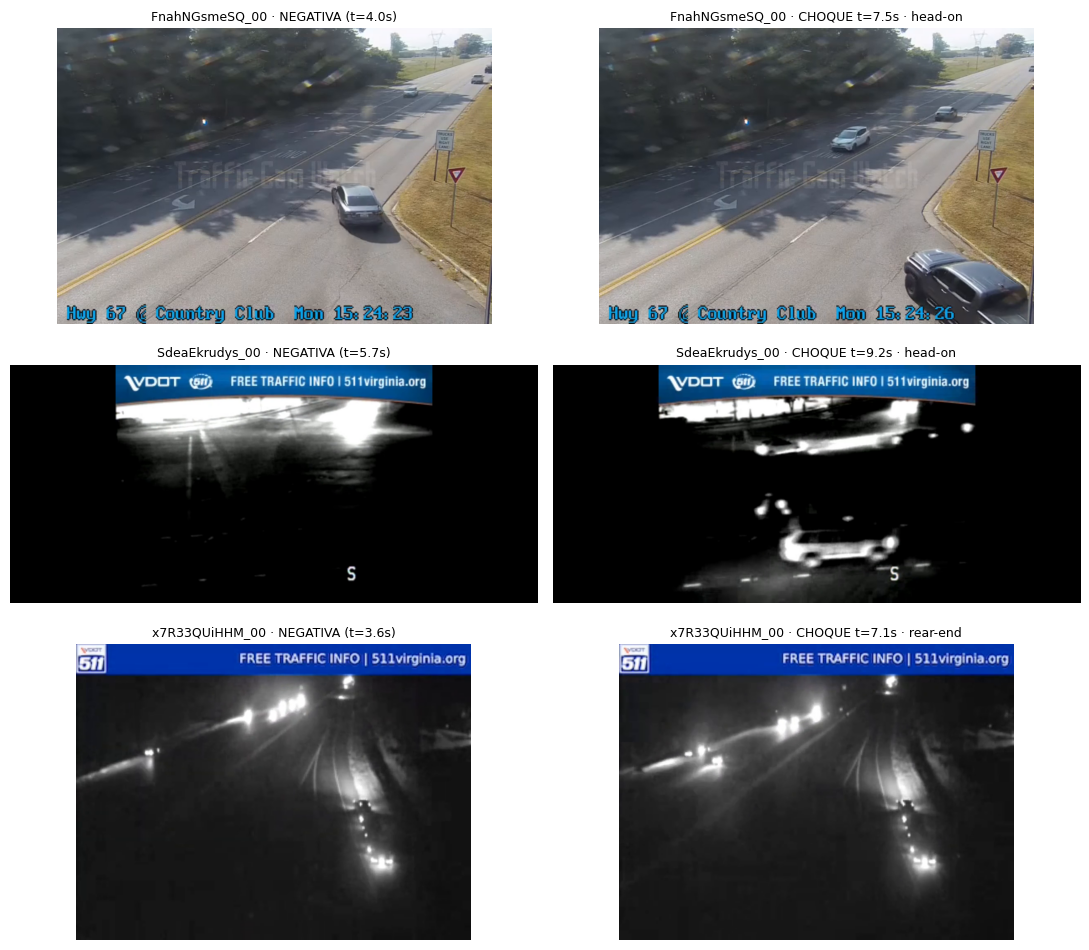

In [ ]:
def frame_en(ruta, seg):
    cap = cv2.VideoCapture(ruta)
    cap.set(cv2.CAP_PROP_POS_MSEC, seg * 1000)
    ok, img = cap.read()
    cap.release()
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if ok else None


con_ambas = VENTANAS.groupby("video").filter(lambda g: len(g) == 2)["video"].unique()[:3]
fig, ejes = plt.subplots(len(con_ambas), 2, figsize=(11, 3.2 * len(con_ambas)), squeeze=False)
for i, vid in enumerate(con_ambas):
    g = VENTANAS[VENTANAS["video"] == vid].set_index("clase")
    neg, pos = g.loc["negativa"], g.loc["positiva"]
    for j, (img, tit) in enumerate([(frame_en(neg["ruta"], neg["fin"] - 0.5), f"NEGATIVA (t={neg['fin']-0.5:.1f}s)"),
                                    (frame_en(pos["ruta"], pos["t_choque"]), f"CHOQUE t={pos['t_choque']:.1f}s · {pos['tipo_real']}")]):
        if img is not None:
            ejes[i, j].imshow(img)
        ejes[i, j].set_title(f"{vid[:20]} · {tit}", fontsize=9); ejes[i, j].axis("off")
plt.tight_layout(); plt.show()

## 5. Cargar Qwen2.5-VL-3B y funciones de R1.2

Mismo código que R1.2. Cambio: si la respuesta sale como `!!!!!!` (pasó en R1.2 con VRU_200: es un desbordamiento numérico de fp16 con muchos tokens), se reintenta automáticamente con la mitad de frames.

In [ ]:
MODO = "fp16"          # "fp16" o "4bit"
MODELO_ID = "Qwen/Qwen2.5-VL-3B-Instruct"
MIN_PIX, MAX_PIX = 256 * 28 * 28, 1024 * 28 * 28

import transformers
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor

_v = tuple(int(x) for x in re.findall(r"\d+", transformers.__version__)[:2])
DTYPE_KW = "dtype" if _v >= (4, 56) else "torch_dtype"
print("transformers", transformers.__version__)

t0 = time.time()
if MODO == "4bit":
    from transformers import BitsAndBytesConfig
    cuant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                               bnb_4bit_compute_dtype=torch.float16)
    modelo = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        MODELO_ID, quantization_config=cuant, device_map="auto", attn_implementation="sdpa")
else:
    modelo = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        MODELO_ID, **{DTYPE_KW: torch.float16}, device_map="auto", attn_implementation="sdpa")
modelo.eval()

try:   # forma nueva
    procesador = AutoProcessor.from_pretrained(
        MODELO_ID, size={"shortest_edge": MIN_PIX, "longest_edge": MAX_PIX})
except (TypeError, ValueError):   # versiones viejas
    procesador = AutoProcessor.from_pretrained(MODELO_ID, min_pixels=MIN_PIX, max_pixels=MAX_PIX)

print(f"Cargado en {time.time() - t0:.0f} s · VRAM usada: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

transformers 5.22.0


config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

... (4 outputs left out)

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Cargado en 92 s · VRAM usada: 7.5 GB


In [ ]:
from qwen_vl_utils import process_vision_info

_CAP_OK = True   # se apaga solo si esta versión de transformers no reconoce cap_pixels_per_frame


def preguntar(contenido, max_new_tokens=256, fps_video=None):
    """Envía un mensaje (lista de partes image/video/text) y devuelve (texto, segundos, entradas)."""
    global _CAP_OK
    mensajes = [{"role": "user", "content": contenido}]
    texto = procesador.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True)
    try:
        imgs, vids, video_kwargs = process_vision_info(mensajes, return_video_kwargs=True)
    except TypeError:
        imgs, vids = process_vision_info(mensajes)
        video_kwargs = {}

    extra = {}
    if vids:
        fps = (video_kwargs or {}).get("fps")
        if isinstance(fps, (list, tuple)):
            fps = fps[0] if fps else None
        if fps_video is not None:          # cuando mandamos frames sueltos, el fps real lo sabemos nosotros
            fps = fps_video
        if fps is not None:
            extra["fps"] = float(fps)
        if _CAP_OK:
            extra["cap_pixels_per_frame"] = True

    try:
        entradas = procesador(text=[texto], images=imgs or None, videos=vids or None, padding=True,
                              return_tensors="pt", **extra)
    except TypeError:
        _CAP_OK = False
        extra.pop("cap_pixels_per_frame", None)
        entradas = procesador(text=[texto], images=imgs or None, videos=vids or None, padding=True,
                              return_tensors="pt", **extra)
    entradas = entradas.to(modelo.device)

    torch.cuda.synchronize()
    t0 = time.time()
    with torch.no_grad():
        salida = modelo.generate(**entradas, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    segundos = time.time() - t0
    nuevos = salida[:, entradas["input_ids"].shape[1]:]
    respuesta = procesador.batch_decode(nuevos, skip_special_tokens=True)[0].strip()
    return respuesta, segundos, entradas


def parece_basura(texto):
    t = texto.strip()
    return len(t) == 0 or len(set(t)) <= 3 or t.count("!") > len(t) * 0.5


def _primer_json(t):
    inicio = min([i for i in (t.find("{"), t.find("[")) if i >= 0], default=-1)
    if inicio < 0:
        return None
    for fin in range(len(t), inicio, -1):
        try:
            return json.loads(t[inicio:fin])
        except json.JSONDecodeError:
            continue
    return None


def _reparar_lineas(t):
    """Pone comillas a valores que no son JSON válido: "clave": 2011-07-04 09:51:13,  ->  "clave": "2011-07-04 09:51:13","""
    salida = []
    for linea in t.splitlines():
        m = re.match(r'^(\s*"[^"]+"\s*:\s*)(.+?)(\s*,?\s*)$', linea)
        if m:
            valor = m.group(2)
            try:
                json.loads(valor)
            except json.JSONDecodeError:
                valor = json.dumps(valor.strip().strip('"'), ensure_ascii=False)
            linea = m.group(1) + valor + m.group(3)
        salida.append(linea)
    return "\n".join(salida)


def extraer_json(texto):
    """Devuelve (objeto_o_None, reparado: bool)."""
    t = re.sub(r"```(?:json)?", "", texto)
    obj = _primer_json(t)
    if obj is not None:
        return obj, False
    obj = _primer_json(_reparar_lineas(t))
    return obj, obj is not None


TIPOS = {"choque_vehiculos", "atropello", "moto_caida", "vehiculo_detenido", "otro", "ninguno"}
FRASES_PLANTILLA = {"una oración en español", "una oracion en español", ""}


def _a_bool(x):
    if isinstance(x, bool):
        return x
    if isinstance(x, str) and x.strip().lower() in ("true", "false", "sí", "si", "no"):
        return x.strip().lower() in ("true", "sí", "si")
    return None


def normalizar_juicio(datos, duracion_s):
    """Valida campos y anota qué estaba mal. Devuelve un dict limpio."""
    problemas = []
    inc = _a_bool(datos.get("incidente"))
    if inc is None:
        problemas.append("incidente")
    tipo = str(datos.get("tipo", "")).strip().lower()
    if tipo not in TIPOS:
        problemas.append("tipo"); tipo = "otro" if inc else "ninguno"
    seg = datos.get("segundo_aprox")
    if not isinstance(seg, (int, float)) or isinstance(seg, bool) or not (0 <= seg <= duracion_s + 1):
        if seg is not None:
            problemas.append("segundo_aprox")
        seg = None
    fija = _a_bool(datos.get("camara_fija"))
    desc = str(datos.get("descripcion", "")).strip()
    if desc.lower() in FRASES_PLANTILLA:
        problemas.append("descripcion")
    return {"incidente": inc, "tipo": tipo, "segundo_aprox": seg, "camara_fija": fija,
            "descripcion": desc, "campos_malos": ",".join(problemas)}


# Prueba rápida del parser con la respuesta real que falló el 22 de octubre
_ejemplo = '```json\n{\n  "incidente": true,\n  "tipo": "atropello",\n  "segundo_aprox": 2011-07-04 09:51:13,\n  "camara_fija": false,\n  "descripcion": "una oración en español"\n}\n```'
_obj, _rep = extraer_json(_ejemplo)
print("reparado:", _rep, "→", normalizar_juicio(_obj, duracion_s=12))

reparado: True → {'incidente': True, 'tipo': 'atropello', 'segundo_aprox': None, 'camara_fija': False, 'descripcion': 'una oración en español', 'campos_malos': 'segundo_aprox,descripcion'}


### Muestreo de una ventana y prompt alineado a ACCIDENT

In [ ]:
FPS_VIDEO = 2.0
MAX_FRAMES = 16
MAX_PIXELES_VIDEO = 360 * 420

TIPOS = {"frontal", "alcance", "en_t", "roce_lateral", "un_vehiculo", "otro", "ninguno"}
MAPEO_TIPO = {   # clase de ACCIDENT (inglés) → clase del JSON
    "head-on": "frontal", "head_on": "frontal", "headon": "frontal",
    "rear-end": "alcance", "rear_end": "alcance", "rearend": "alcance",
    "t-bone": "en_t", "t_bone": "en_t", "tbone": "en_t",
    "sideswipe": "roce_lateral", "side-swipe": "roce_lateral",
    "single": "un_vehiculo", "single-vehicle": "un_vehiculo", "single_vehicle": "un_vehiculo",
}


def tipo_json(valor):
    v = str(valor).strip().lower()
    return MAPEO_TIPO.get(v, MAPEO_TIPO.get(v.replace(" ", "-"), "otro"))


def muestrear_ventana(ruta, inicio, fin, max_frames=MAX_FRAMES, carpeta_id=""):
    fps, total, dur, ancho, alto = info_video(ruta)
    largo = fin - inicio
    n = int(min(max_frames, max(2, largo * FPS_VIDEO)))
    n -= n % 2
    tiempos = [inicio + i * largo / n for i in range(n)]
    escala = min(1.0, (MAX_PIXELES_VIDEO / (ancho * alto)) ** 0.5)
    tam = (max(28, int(ancho * escala)), max(28, int(alto * escala)))
    carpeta = os.path.join(DIR_CLIPS, carpeta_id)
    shutil.rmtree(carpeta, ignore_errors=True); os.makedirs(carpeta, exist_ok=True)
    cap = cv2.VideoCapture(ruta)
    rutas = []
    for k, t in enumerate(tiempos):
        cap.set(cv2.CAP_PROP_POS_MSEC, t * 1000)
        ok, img = cap.read()
        if ok:
            r = os.path.join(carpeta, f"{k:03d}.jpg")
            cv2.imwrite(r, cv2.resize(img, tam, interpolation=cv2.INTER_AREA))
            rutas.append(r)
    cap.release()
    if len(rutas) % 2:
        rutas = rutas[:-1]
    return rutas, (len(rutas) / largo if largo > 0 else FPS_VIDEO), largo


PROMPT_INCIDENTE = (
    "Eres operador de un centro de monitoreo de tráfico (C5). Mira el video de una cámara de vigilancia "
    "y decide si ocurre un choque.\n"
    "El video dura {dur:.0f} segundos.\n"
    "Responde SOLO con un objeto JSON con estas claves:\n"
    "- incidente: true o false\n"
    "- tipo: una de frontal, alcance, en_t, roce_lateral, un_vehiculo, otro, ninguno "
    "(alcance = un vehículo pega por detrás a otro; en_t = un vehículo pega en el costado de otro en un cruce; "
    "roce_lateral = dos vehículos se rozan de lado; un_vehiculo = choca solo contra un objeto; "
    "ninguno si incidente es false)\n"
    "- segundo_aprox: segundo en que ocurre el choque, un número entre 0 y {dur:.0f}; null si no hay choque\n"
    "- camara_fija: true si la cámara está quieta (poste o vigilancia), false si va dentro de un vehículo\n"
    "- descripcion: una oración en español que diga lo que se ve\n"
    "Ignora fechas, horas, velocidades y logotipos sobreimpresos en la imagen.\n"
    "Ejemplo de formato con valores inventados:\n"
    '{{"incidente": false, "tipo": "ninguno", "segundo_aprox": null, "camara_fija": true, '
    '"descripcion": "Tráfico fluido en una avenida de dos carriles sin eventos."}}'
)


def juzgar_ventana(v, idx):
    frames_max = MAX_FRAMES
    for intento in range(2):
        rutas, fps_ef, dur = muestrear_ventana(v["ruta"], v["inicio"], v["fin"], frames_max, f"v{idx:04d}")
        if len(rutas) < 2:
            return {"incidente": None, "tipo": "video_ilegible", "formato": "sin_video"}
        resp, seg, entradas = preguntar([
            {"type": "video", "video": [f"file://{r}" for r in rutas]},
            {"type": "text", "text": PROMPT_INCIDENTE.format(dur=dur)},
        ], max_new_tokens=200, fps_video=fps_ef)
        if not parece_basura(resp):
            break
        frames_max = max(4, frames_max // 2)      # reintento con menos frames
    datos, reparado = extraer_json(resp)
    if isinstance(datos, dict):
        r = normalizar_juicio(datos, dur)
        r["formato"] = "reparado" if reparado else "ok"
    else:
        r = {"incidente": None, "tipo": "sin_json", "formato": "irrecuperable"}
    r.update({"segundos": round(seg, 2), "tokens_entrada": int(entradas["input_ids"].shape[1]),
              "frames": len(rutas), "reintento": intento > 0, "respuesta_cruda": resp})
    return r


print(PROMPT_INCIDENTE.format(dur=8))

Eres operador de un centro de monitoreo de tráfico (C5). Mira el video de una cámara de vigilancia y decide si ocurre un choque.
El video dura 8 segundos.
Responde SOLO con un objeto JSON con estas claves:
- incidente: true o false
- tipo: una de frontal, alcance, en_t, roce_lateral, un_vehiculo, otro, ninguno (alcance = un vehículo pega por detrás a otro; en_t = un vehículo pega en el costado de otro en un cruce; roce_lateral = dos vehículos se rozan de lado; un_vehiculo = choca solo contra un objeto; ninguno si incidente es false)
- segundo_aprox: segundo en que ocurre el choque, un número entre 0 y 8; null si no hay choque
- camara_fija: true si la cámara está quieta (poste o vigilancia), false si va dentro de un vehículo
- descripcion: una oración en español que diga lo que se ve
Ignora fechas, horas, velocidades y logotipos sobreimpresos en la imagen.
Ejemplo de formato con valores inventados:
{"incidente": false, "tipo": "ninguno", "segundo_aprox": null, "camara_fija": true, "des

## 6. Línea base oficial: todas las ventanas

Con 60 ventanas a ~6 s cada una son unos **6 minutos**. Cada 10 ventanas se guarda el CSV, por si Colab se desconecta.

In [ ]:
salida_csv = os.path.join(DIR_RESULTADOS, f"linea_base_accident_{time.strftime('%Y%m%d_%H%M')}.csv")
filas = []
for i, v in VENTANAS.reset_index(drop=True).iterrows():
    try:
        r = juzgar_ventana(v, i)
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache()
        r = {"incidente": None, "tipo": "sin_memoria", "formato": "sin_memoria"}
    fila = {**v.to_dict(), **{f"pred_{k}" if k in ("incidente", "tipo", "segundo_aprox") else k: val
                              for k, val in r.items()}}
    filas.append(fila)
    print(f"[{i+1}/{len(VENTANAS)}] {v['clase']:8s} {v['video'][:22]:22s} → {r.get('incidente')} · "
          f"{r.get('tipo')} · {r.get('formato')} · {r.get('segundos')} s")
    if (i + 1) % 10 == 0:
        pd.DataFrame(filas).to_csv(salida_csv, index=False)

res = pd.DataFrame(filas)
res.to_csv(salida_csv, index=False)
print("Guardado en", salida_csv)

[1/38] positiva FnahNGsmeSQ_00         → True · en_t · ok · 9.48 s
[2/38] negativa FnahNGsmeSQ_00         → True · en_t · ok · 4.65 s
[3/38] positiva tqSAFTzuCy4_00         → True · en_t · ok · 6.24 s
[4/38] positiva aDBb3QMnKZc_00         → True · en_t · ok · 6.24 s
[5/38] positiva O0v2MBUkTGk_00         → True · en_t · ok · 5.65 s
[6/38] positiva SdeaEkrudys_00         → True · en_t · ok · 6.22 s
[7/38] negativa SdeaEkrudys_00         → True · en_t · ok · 5.28 s
[8/38] positiva 91JpOFnaiD4_00         → True · en_t · ok · 5.79 s
[9/38] positiva 8ZzJdjQi-aM_00         → True · en_t · ok · 6.21 s
[10/38] positiva x7R33QUiHHM_00         → True · en_t · ok · 6.89 s
[11/38] negativa x7R33QUiHHM_00         → True · en_t · ok · 4.47 s
[12/38] positiva dfEFaPk-2-Y_00         → True · en_t · ok · 6.36 s
[13/38] positiva qfCt6R_rTMY_00         → True · en_t · ok · 5.78 s
[14/38] positiva T5396f4sJ5w_00         → False · ninguno · ok · 5.34 s
[15/38] negativa T5396f4sJ5w_00         → True · en_t

## 7. Métricas

- **Matriz de confusión** sobre `incidente` (positiva vs. negativa).
- **Precision**: de las veces que dijo "choque", ¿cuántas había? (baja = muchas falsas alarmas).
- **Recall**: de los choques, ¿cuántos vio?
- **Tasa de falsas alarmas (FPR)**: de las ventanas sin choque, ¿en cuántas dijo "choque"?
- **Tipo**: % de acierto en positivas (5 clases; al azar sería ~20 %).
- **Tiempo**: error en segundos entre `segundo_aprox` y el choque real, y % dentro de ±2 s.

Las respuestas que no se pudieron leer cuentan como **"no detectó"** (en producción tampoco habría alerta).

In [ ]:
leg = res.copy()
leg["y_real"] = leg["clase"] == "positiva"
leg["y_pred"] = leg["pred_incidente"].fillna(False).astype(bool)

vp = int((leg.y_real & leg.y_pred).sum()); fn = int((leg.y_real & ~leg.y_pred).sum())
fp = int((~leg.y_real & leg.y_pred).sum()); vn = int((~leg.y_real & ~leg.y_pred).sum())
precision = vp / (vp + fp) if vp + fp else float("nan")
recall = vp / (vp + fn) if vp + fn else float("nan")
fpr = fp / (fp + vn) if fp + vn else float("nan")
f1 = 2 * precision * recall / (precision + recall) if precision + recall else float("nan")

display(Markdown(f"""
|  | predijo choque | predijo nada |
|---|---|---|
| **había choque** | VP = {vp} | FN = {fn} |
| **no había** | FP = {fp} | VN = {vn} |
"""))
print(f"Precision {precision:.0%} · Recall {recall:.0%} · F1 {f1:.2f} · Falsas alarmas (FPR) {fpr:.0%}")

fmt = res["formato"].value_counts().to_dict()
print(f"Formato: ok {fmt.get('ok',0)} · reparado {fmt.get('reparado',0)} · irrecuperable {fmt.get('irrecuperable',0)} "
      f"· reintentos por '!!!!' {int(res.get('reintento', pd.Series(dtype=bool)).fillna(False).sum())}")

pos = leg[leg.y_real & leg.y_pred].copy()
if len(pos) and COL["tipo"]:
    pos["tipo_esperado"] = pos["tipo_real"].map(tipo_json)
    print(f"\nTipo correcto (en positivas detectadas): {(pos['pred_tipo'] == pos['tipo_esperado']).mean():.0%} "
          f"(azar ≈ 20 %)")
    display(pd.crosstab(pos["tipo_esperado"], pos["pred_tipo"], margins=True))
con_t = pos[pos["pred_segundo_aprox"].notna()] if len(pos) else pos
if len(con_t):
    err = (con_t["pred_segundo_aprox"] - con_t["t_rel"]).abs()
    print(f"Tiempo: {len(con_t)}/{len(pos)} con segundo · error mediano {err.median():.1f} s · "
          f"dentro de ±2 s: {(err <= 2).mean():.0%}")

lat = res["segundos"].dropna()
print(f"\nLatencia: mediana {lat.median():.1f} s · máx {lat.max():.1f} s")
print(f"camara_fija = true en {res['camara_fija'].eq(True).mean():.0%} de las ventanas (deberían ser casi todas: es CCTV)")

# Falsas alarmas por cámara por hora, si el detector mandara una ventana cada X minutos de tráfico normal
VENTANAS_SOSPECHOSAS_POR_HORA = 6
print(f"\nSi el detector (paso 1-2) manda {VENTANAS_SOSPECHOSAS_POR_HORA} ventanas sin choque por cámara por hora, "
      f"el supervisor dejaría pasar ≈ {fpr * VENTANAS_SOSPECHOSAS_POR_HORA:.1f} falsas alarmas/cámara/hora.")


|  | predijo choque | predijo nada |
|---|---|---|
| **había choque** | VP = 29 | FN = 1 |
| **no había** | FP = 8 | VN = 0 |


Precision 78% · Recall 97% · F1 0.87 · Falsas alarmas (FPR) 100%
Formato: ok 38 · reparado 0 · irrecuperable 0 · reintentos por '!!!!' 0

Tipo correcto (en positivas detectadas): 21% (azar ≈ 20 %)


pred_tipo,en_t,All
tipo_esperado,,
alcance,5,5
en_t,6,6
frontal,6,6
roce_lateral,6,6
un_vehiculo,6,6
All,29,29


Tiempo: 28/29 con segundo · error mediano 1.2 s · dentro de ±2 s: 82%

Latencia: mediana 6.2 s · máx 9.5 s
camara_fija = true en 97% de las ventanas (deberían ser casi todas: es CCTV)

Si el detector (paso 1-2) manda 6 ventanas sin choque por cámara por hora, el supervisor dejaría pasar ≈ 6.0 falsas alarmas/cámara/hora.


### Dónde se equivoca

Las falsas alarmas y los choques perdidos, con la descripción del modelo. Estos son los casos que el LoRA tiene que arreglar; anota si se repiten patrones (noche, lluvia, cámara lejana, choque leve).

In [ ]:
cols_ver = ["clase", "video", "tipo_real", "pred_incidente", "pred_tipo", "pred_segundo_aprox", "t_rel", "descripcion"]
print("FALSAS ALARMAS (negativa → dijo choque)")
display(leg[~leg.y_real & leg.y_pred][[c for c in cols_ver if c in leg.columns]])
print("CHOQUES PERDIDOS (positiva → dijo nada)")
display(leg[leg.y_real & ~leg.y_pred][[c for c in cols_ver if c in leg.columns]])

FALSAS ALARMAS (negativa → dijo choque)


,clase,video,tipo_real,pred_incidente,pred_tipo,pred_segundo_aprox,t_rel,descripcion
1,negativa,FnahNGsmeSQ_00,head-on,True,en_t,NaN,NaN,Un vehículo se detiene abruptamente en el cruc...
6,negativa,SdeaEkrudys_00,head-on,True,en_t,3.0,NaN,Un vehículo se detiene abruptamente en la carr...
10,negativa,x7R33QUiHHM_00,rear-end,True,en_t,2.0,NaN,Un vehículo se detiene abruptamente en medio d...
14,negativa,T5396f4sJ5w_00,rear-end,True,en_t,4.0,NaN,Un vehículo se detiene abruptamente en el carr...
25,negativa,vR3sZ1IxPAo_00,single,True,en_t,3.0,NaN,Un vehículo se detiene abruptamente en el carr...
31,negativa,jiliVB6lsKE_00,t-bone,True,en_t,2.0,NaN,Un vehículo se detiene abruptamente en el cruc...
34,negativa,bSq7XtY629s_00,t-bone,True,en_t,3.0,NaN,Un vehículo se detiene bruscamente en el carri...
37,negativa,tK1wd_HCYNo_00,t-bone,True,en_t,3.0,NaN,Un vehículo se detiene abruptamente en el carr...


CHOQUES PERDIDOS (positiva → dijo nada)


,clase,video,tipo_real,pred_incidente,pred_tipo,pred_segundo_aprox,t_rel,descripcion
13,positiva,T5396f4sJ5w_00,rear-end,False,ninguno,NaN,6.040564,Tráfico fluido en una autopista con varios veh...


## Qué sigue (R2: el LoRA)

1. Con los resultados de aquí, esta tabla **es la línea base oficial**. El LoRA se evalúa con **las mismas ventanas** (guarda el CSV en Drive).
2. Para entrenar: cortar ventanas de **otros** videos (nunca los de esta muestra de prueba) y de los **sintéticos** de CARLA. Cada ventana → par (frames, JSON correcto). Positivas y negativas en proporción ~1:1.
3. Split por video/fuente (no por ventana) para evitar fuga de casi duplicados.

In [ ]:
   from google.colab import drive; drive.mount("/content/drive")
   !mkdir -p /content/drive/MyDrive/roadvision/resultados_qwen
   !cp /content/datos_roadvision/resultados_qwen/linea_base_accident_20261103_1711.csv /content/drive/MyDrive/roadvision/resultados_qwen/

Mounted at /content/drive
cp: cannot stat '/content/datos_roadvision/resultados_qwen/linea_base_accident_20261103_1711.csv': No such file or directory
